TensorFlow version:
2.22.0-rc0

Image size:
(224, 224)

Batch size:
32

Project root:
c:\Users\24105A2006\Desktop\Tumor_Detection\Tumor_Detection

Data root:
c:\Users\24105A2006\Desktop\Tumor_Detection\Tumor_Detection\data\raw

Training directory:
c:\Users\24105A2006\Desktop\Tumor_Detection\Tumor_Detection\data\raw\Training

Testing directory:
c:\Users\24105A2006\Desktop\Tumor_Detection\Tumor_Detection\data\raw\Testing

Classes:
['glioma', 'meningioma', 'notumor', 'pituitary']

Number of classes:
4

Image count before preprocessing
glioma          Training:  1400 | Testing:   400
meningioma      Training:  1400 | Testing:   400
notumor         Training:  1400 | Testing:   400
pituitary       Training:  1400 | Testing:   400
Found 5600 files belonging to 4 classes.
Using 4480 files for training.
Found 5600 files belonging to 4 classes.
Using 1120 files for validation.
Found 1600 files belonging to 4 classes.

Dataset information
Training batches: 140
Validation batches: 35
Testing batch

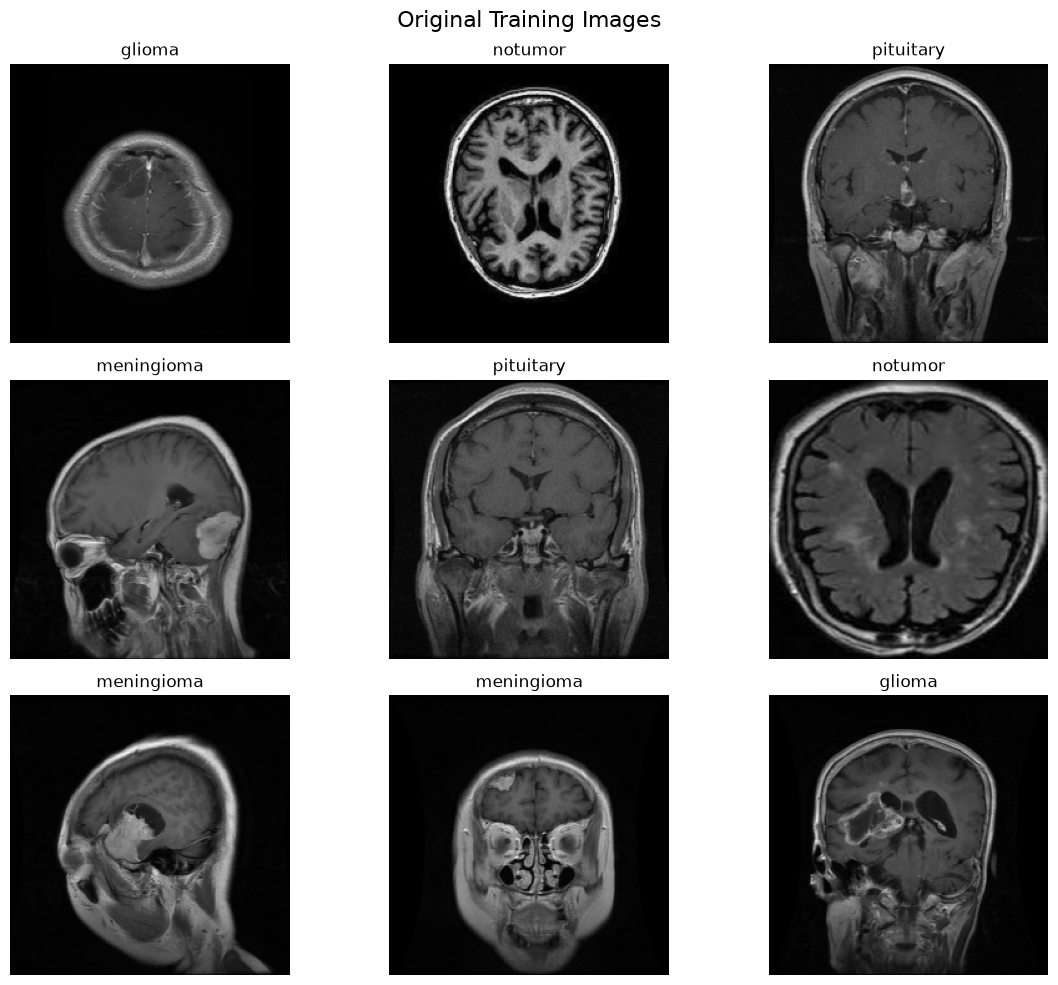

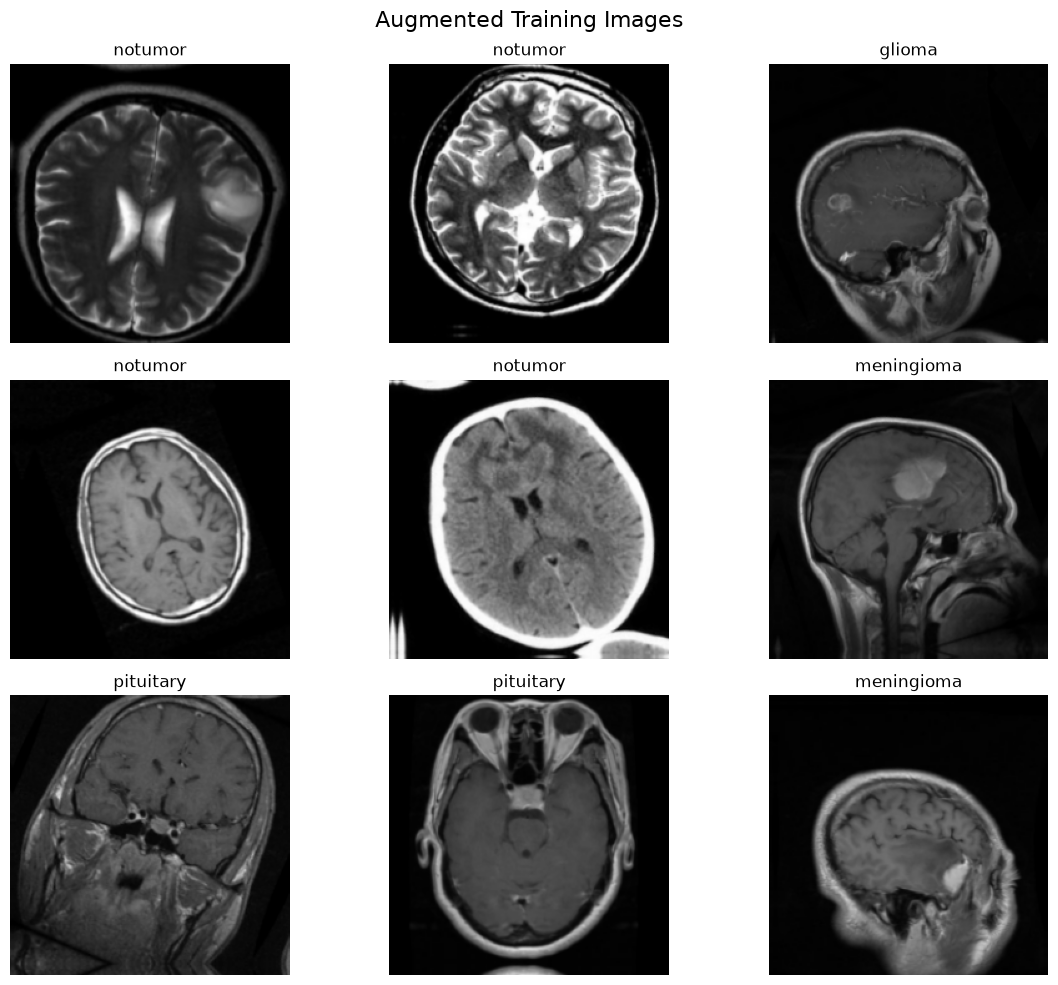


One training batch
Image batch shape: (32, 224, 224, 3)
Label batch shape: (32, 4)
Image data type: <dtype: 'float32'>
Minimum pixel value: 0.0
Maximum pixel value: 255.0


DATA PREPROCESSING COMPLETED
Image size       : (224, 224)
Batch size       : 32
Validation split : 0.2
Classes          : ['glioma', 'meningioma', 'notumor', 'pituitary']

Datasets ready:
train_dataset
validation_dataset
test_dataset

Data augmentation:
RandomRotation
RandomZoom
RandomTranslation

Next notebook:
03_cnn_baseline.ipynb


In [ ]:
# Data Preprocessing

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# BASIC SETTINGS

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42
VALIDATION_SPLIT = 0.20

print("TensorFlow version:")
print(tf.__version__)

print("\nImage size:")
print(IMG_SIZE)

print("\nBatch size:")
print(BATCH_SIZE)

#FIND PROJECT ROOT

CURRENT_DIR = Path.cwd()

PROJECT_ROOT = None

for path in [CURRENT_DIR] + list(CURRENT_DIR.parents):

    if (path / "data" / "raw").exists():

        PROJECT_ROOT = path
        break


if PROJECT_ROOT is None:

    raise FileNotFoundError(
        "Could not find project root containing data/raw."
    )


DATA_ROOT = PROJECT_ROOT / "data" / "raw"


print("\nProject root:")
print(PROJECT_ROOT)

print("\nData root:")
print(DATA_ROOT)

#FIND TRAINING AND TESTING FOLDERS

def find_folder(root, folder_name):

    matches = [
        path
        for path in root.rglob(folder_name)
        if path.is_dir()
    ]

    if not matches:

        raise FileNotFoundError(
            f"Could not find '{folder_name}' inside:\n{root}"
        )

    return matches[0]


TRAIN_DIR = find_folder(
    DATA_ROOT,
    "Training"
)

TEST_DIR = find_folder(
    DATA_ROOT,
    "Testing"
)


print("\nTraining directory:")
print(TRAIN_DIR)

print("\nTesting directory:")
print(TEST_DIR)

# 4. CHECK CLASS FOLDERS

CLASS_NAMES = sorted([
    folder.name
    for folder in TRAIN_DIR.iterdir()
    if folder.is_dir()
])


print("\nClasses:")
print(CLASS_NAMES)

print("\nNumber of classes:")
print(len(CLASS_NAMES))

#CHECK IMAGE FILES BEFORE LOADING

IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp"
}


def count_images(folder):

    return sum(
        1
        for file in folder.rglob("*")
        if (
            file.is_file()
            and file.suffix.lower()
            in IMAGE_EXTENSIONS
        )
    )


print("\nImage count before preprocessing")
print("=" * 50)


for class_name in CLASS_NAMES:

    train_count = count_images(
        TRAIN_DIR / class_name
    )

    test_count = count_images(
        TEST_DIR / class_name
    )

    print(
        f"{class_name:15s} "
        f"Training: {train_count:5d} | "
        f"Testing: {test_count:5d}"
    )


#LOAD TRAINING DATA

train_dataset = tf.keras.utils.image_dataset_from_directory(

    TRAIN_DIR,

    labels="inferred",

    label_mode="categorical",

    class_names=CLASS_NAMES,

    image_size=IMG_SIZE,

    batch_size=BATCH_SIZE,

    validation_split=VALIDATION_SPLIT,

    subset="training",

    seed=SEED,

    shuffle=True
)

#LOAD VALIDATION DATA

validation_dataset = tf.keras.utils.image_dataset_from_directory(

    TRAIN_DIR,

    labels="inferred",

    label_mode="categorical",

    class_names=CLASS_NAMES,

    image_size=IMG_SIZE,

    batch_size=BATCH_SIZE,

    validation_split=VALIDATION_SPLIT,

    subset="validation",

    seed=SEED,

    shuffle=True
)

# LOAD TESTING DATA

test_dataset = tf.keras.utils.image_dataset_from_directory(

    TEST_DIR,

    labels="inferred",

    label_mode="categorical",

    class_names=CLASS_NAMES,

    image_size=IMG_SIZE,

    batch_size=BATCH_SIZE,

    shuffle=False
)


#  DISPLAY DATASET INFORMATION

print("\nDataset information")
print("=" * 50)

print(
    "Training batches:",
    tf.data.experimental.cardinality(
        train_dataset
    ).numpy()
)

print(
    "Validation batches:",
    tf.data.experimental.cardinality(
        validation_dataset
    ).numpy()
)

print(
    "Testing batches:",
    tf.data.experimental.cardinality(
        test_dataset
    ).numpy()
)


print("\nClass names:")
print(
    train_dataset.class_names
)

# NORMALIZATION / DATA AUGMENTATION

data_augmentation = tf.keras.Sequential([

    tf.keras.layers.RandomRotation(
        0.08
    ),

    tf.keras.layers.RandomZoom(
        0.10
    ),

    tf.keras.layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05
    )

], name="data_augmentation")

# VISUALIZE ORIGINAL IMAGES

plt.figure(figsize=(12, 10))

for images, labels in train_dataset.take(1):

    for i in range(min(9, len(images))):

        ax = plt.subplot(3, 3, i + 1)

        plt.imshow(
            images[i].numpy().astype("uint8")
        )

        label_index = np.argmax(
            labels[i].numpy()
        )

        plt.title(
            CLASS_NAMES[label_index]
        )

        plt.axis("off")


plt.suptitle(
    "Original Training Images",
    fontsize=16
)

plt.tight_layout()

plt.show()


# VISUALIZE AUGMENTED IMAGES

plt.figure(figsize=(12, 10))

for images, labels in train_dataset.take(1):

    augmented_images = data_augmentation(
        images,
        training=True
    )

    for i in range(min(9, len(images))):

        ax = plt.subplot(3, 3, i + 1)

        plt.imshow(
            tf.clip_by_value(
                augmented_images[i],
                0,
                255
            ).numpy().astype("uint8")
        )

        label_index = np.argmax(
            labels[i].numpy()
        )

        plt.title(
            CLASS_NAMES[label_index]
        )

        plt.axis("off")


plt.suptitle(
    "Augmented Training Images",
    fontsize=16
)

plt.tight_layout()

plt.show()

# PREFETCH FOR PERFORMANCE

AUTOTUNE = tf.data.AUTOTUNE


train_dataset = train_dataset.prefetch(
    buffer_size=AUTOTUNE
)

validation_dataset = validation_dataset.prefetch(
    buffer_size=AUTOTUNE
)

test_dataset = test_dataset.prefetch(
    buffer_size=AUTOTUNE
)

# CHECK ONE BATCH

for images, labels in train_dataset.take(1):

    print("\nOne training batch")
    print("=" * 50)

    print(
        "Image batch shape:",
        images.shape
    )

    print(
        "Label batch shape:",
        labels.shape
    )

    print(
        "Image data type:",
        images.dtype
    )

    print(
        "Minimum pixel value:",
        tf.reduce_min(images).numpy()
    )

    print(
        "Maximum pixel value:",
        tf.reduce_max(images).numpy()
    )



# FINAL SUMMARY


print("\n")
print("=" * 60)
print("DATA PREPROCESSING COMPLETED")
print("=" * 60)

print(
    f"Image size       : {IMG_SIZE}"
)

print(
    f"Batch size       : {BATCH_SIZE}"
)

print(
    f"Validation split : {VALIDATION_SPLIT}"
)

print(
    f"Classes          : {CLASS_NAMES}"
)

print(
    "\nDatasets ready:"
)

print(
    "train_dataset"
)

print(
    "validation_dataset"
)

print(
    "test_dataset"
)

print(
    "\nData augmentation:"
)

print(
    "RandomRotation"
)

print(
    "RandomZoom"
)

print(
    "RandomTranslation"
)

print(
    "\nNext notebook:"
)

print(
    "03_cnn_baseline.ipynb"
)